# Индивидуальная КТ/FEM-проверка трёх участников Scorpion

**Сводка завершённого ограниченного вычислительного цикла.** Исследовательский этап разработки методики, 26 октября 2026 года.

Цель — проверить, что объясняют индивидуальные прямые модели базового импеданса,
какие тканевые параметры различимы локально и как условные тканевые и объёмные
сценарии изменяют электрический ответ. Представлены три самостоятельные модели;
данные между участниками не переносятся. Георгий, Ник и Ярослав — принятые
проектом псевдонимы; ФИО и пространственные исходники не раскрываются.

**Авторское решение о дальнейшей схеме.** Конечным входом методики принят
сигнал ТТРКГ. Боковые сборки исключены из дальнейшей схемы определения
тканевых ρ; их результаты сохраняются здесь как отрицательная диагностическая
проверка и не предлагаются в качестве рабочей инверсии сопротивлений.
Текущий вычислительный цикл сохраняет полный набор сравнений для разбора
полученного отрицательного результата.

Проверки численного решения и интегрирования пройдены в указанном ниже объёме.
Совпадение с экспериментальными уровнями и практическая идентифицируемость
параметров этим не установлены. Шесть пробных переносов электродов отклонены
до проверки новых площадок. Готовность расчётов замещения сердца: 24 из 24;
новых материальных ветвей: 6 из 6.
Все таблицы раскрываются по действию читателя.

1. [Входы, прямая модель и контроль](#inputs)
2. [Базовые уровни и временное разделение](#baseline)
3. [Парное дыхательное различие](#breath)
4. [Различимость сопротивлений](#svd)
5. [Четыре тканевых возмущения](#basis)
6. [Объём эквивалентной сферы](#sphere)
7. [Авторский диапазон сопротивлений](#range)
8. [Вывод и происхождение](#conclusion)

In [1]:
from pathlib import Path
import sys,json
here=Path.cwd()
folder=here if (here/'build_scorpion_fem_smart_report.py').is_file() else next(p/'Colab Notebooks/scorpion_v2' for p in [here,*here.parents] if (p/'Colab Notebooks/scorpion_v2/build_scorpion_fem_smart_report.py').is_file())
sys.path.insert(0,str(folder))
import build_scorpion_fem_smart_report as F
from IPython.display import HTML,display
get_ipython().run_line_magic('matplotlib','inline')
S=json.loads((folder/'_assets/fem_smart_20261026.summary.json').read_text(encoding='utf-8'))
F.assert_safe(S)

<a id="inputs"></a>
## 1. Индивидуальные входы, прямая модель и границы проверок

**Подтверждённые входы.** Использованы собственные КТ и подготовленные сетки трёх
участников. КТ получены на глубоком вдохе с задержкой дыхания. Фон, лёгкое,
кость, всё сердце и жир образуют пять материалов. Индивидуальная геометрия
и собственные маски TotalSegmentator v2.18.0 служат входами прямого расчёта.
Паспорта связывают исходную КТ и каждую маску SHA; для сетки используются
отдельные маски вычислительной области. Нативные анатомические STL и сетки
вычислительной области сохраняют разные назначения. Анатомический просмотр
автоматических масок остаётся отдельной проверкой. Качество электрического прогноза
не следует из одного успешного геометрического контроля.

**Модельные допущения.** Расчёт выполнен при 100 кГц в MATLAB/EIDORS с конечными
контактами в полной электродной модели (CEM), методом конечных элементов (FEM):
номинальные диски диаметром 5 мм, фактические дискретные площадки
и группировка физически присутствующих электродов. Контактный импеданс задан
сценарием. Кость фиксирована. Сердце рассматривается как единая эффективная
область, без разделения крови и миокарда. Система решается в СИ; передаточный
импеданс — отношение напряжения к току, в омах.

В реализации используются вещественные удельные сопротивления и проводимости
σ=1/ρ. Комплексные проводимости тканей не используются.

**Смешанные ткани внутри элемента.** В каждом тетраэдре fₖ — объёмная доля
ткани k, fₖ≥0 и Σₖfₖ=1. Для линейных тетраэдральных элементов используется
эффективная проводимость σeff=Σₖfₖ/ρₖ. Усредняется проводимость, а не
арифметическое значение удельного сопротивления. Тканевые матрицы Kₖ
учитывают доли ткани и геометрию элементов; объёмная матрица проводимости
собирается как K=ΣₖKₖ/ρₖ. Это соответствует сохранённой сборке
Fᵀdiag(fₖ)F с повторением весов для трёх компонент поля. Контактные члены
полной электродной модели добавляются отдельно. При изменении ρ в авторской
сетке сценариев индивидуальные тканевые доли и геометрия сохраняются.

Для всех контактов
трёх участников задано zcontact=0,01 Ом·м²; это рабочий CEM-сценарий,
контактный импеданс независимо не измерен. Числа и основание назначения
связаны с сохранённым контактным паспортом.

Цилиндрические руки имеют принятый обхват 370 мм и радиус 370/(2π)≈58,89 мм.
Для Георгия это указание автора от 08.10.2026, для Ника — от 22.10.2026;
для Ярослава это приближённое назначение. Эти разные статусы не объединяются
в утверждение о трёх одинаково измеренных обхватах.

Для оценки вычислительной согласованности сопоставляются невязка линейной
системы и взаимность с допусками 10⁻⁷, производные с центральной разностью
по lnρ с шагом 0,001 и относительным допуском 10⁻⁴. Правила q1024/q4096
используют вложенные наборы из 1024 и 4096 точек Sobol для оценки fₖ внутри
прежних линейных тетраэдров; первые 1024 точки входят в набор 4096.
Число тетраэдров и узлов при этом не растёт. Такой контроль интегрирования
не устраняет ошибку пространственной дискретизации и не доказывает сеточную
сходимость по одной неизменной сетке. Различие правил
проверяется для базовых уровней по критерию 0,02 Ом + 0,001·|Zq4096|.
Таблица 1 показывает фактический охват сохранённых проверок.

**Параметры контрольного расчёта.** Георгий / Ник / Ярослав: фон 2,763585998; лёгкое на вдохе 9,315252925, в условном сценарии выдоха 3,681694081; кость 48,097673526; целое сердце 4,648809058; жир 23,040605218 Ом·м. Источник — частотные значения Gabriel при 100 кГц в [числовом реестре тканей](../../MATLAB_TRKG4_real_subjects/configs/tissue_literature_v2.json), его SHA связан с каждым расчётом. В новой ветви с однородной кровью жир и кость сохраняют именно эти значения. Индивидуальная подгонка не выполнялась. Число знаков отражает сохранённый числовой профиль и не задаёт метрологическую точность. Одинаковые опорные свойства не означают одинаковых индивидуальных геометрий или чувствительностей.

In [2]:
display(HTML(F.qc_table(S)))

Участник,Систем,Макс. невязка,"Взаимность, Ом",FD: макс. относительная ошибка,q1024/q4096
Георгий,28,"4,23793e-14","8,52651e-14","7,89084e-08",Пройден
Ник,16,"1,66579e-14","8,52651e-14","8,05192e-08",Пройден
Ярослав,16,"1,79207e-14","5,68434e-14","1,17232e-07",Пройден


FD-проверка выполнена для монтажа 140 мм с ТТРКГ 2×2 на вдохе; остальные
монтажи и условный выдох не получили отдельной FD-проверки. Сеточная сходимость,
ошибка сегментации и экспериментальная точность остаются самостоятельными
вопросами. При переносе на пять миллиметров сначала проверялась проекция новых
центров на прежнюю поверхность (таблица 2).

In [3]:
display(HTML(F.placement_table(S)))

Участник,"Сдвиг Y, мм","Проекция: минимум, мм","Проекция: максимум, мм",Статус
Георгий,-5,"1,1151","2,01318",ct_fem:projection
Георгий,5,"0,654744","1,86865",ct_fem:projection
Ник,-5,"1,67938","2,3153",ct_fem:projection
Ник,5,"1,53752","2,65117",ct_fem:projection
Ярослав,-5,"1,19296","2,50283",ct_fem:projection
Ярослав,5,"1,36006","2,59011",ct_fem:projection


**Отрицательный результат проверки размещения.** Все шесть сценариев
остановились на прежнем допуске проекции 1 мм. Задавалось смещение исходного
центра на [0,±5,0] мм в LPS перед проекцией; геодезическая длина не фиксировалась.
Допуски не расширялись. Этот отказ относится к геометрической операции по
заданной оси: новые footprint и электрическая устойчивость к размещению
остались непроверенными. Необходимость сгущения сетки данным отказом не установлена.
Сценарные ±5 мм не являются доверительной погрешностью наклейки.

<a id="baseline"></a>
## 2. Базовые уровни при временном разделении каналов

**Экспериментальные наблюдения.** Сопоставляются сохранённые уровни на
ретроспективно выделенных интервалах дыхательного протокола. Разметка остаётся
кандидатной; повторения одного монтажа сведены медианой, число повторений
сохраняется в агрегате. Разные размеры регистрировались последовательно.
Время, контакт и состояние участника могут различаться между записями.

У Георгия вариант ТТРКГ 1×1 в записях 007–010 подтверждён автором.
При этом соответствие физических ролей отведений в записях 008–010
остаётся допущением сохранения подключения; подтверждение варианта ТТРКГ
не превращает это допущение в подтверждённый факт о ролях отведений.

**Подтверждённый режим прибора.** По прямому уточнению автора от 26.10.2026
каналы Scorpion разделяются по времени. Относительная фаза одновременно
действующих источников к этому режиму не применима. Основной прогноз
использует собственный источник отведения — own_drive — и соответствует
подтверждённому временному разделению. Сохранённые решения с отдельными
правыми частями уже дают требуемые портовые ответы; пересчёт прямой задачи
для этого уточнения не требуется. Геометрия, свойства тканей и контактные
условия остаются заданными модельными предпосылками.
Проверим отдельно размерную зависимость и варианты ТТРКГ.

Сравнение на вдохе сохраняет различия размеров и группировки электродов (рисунок 1).

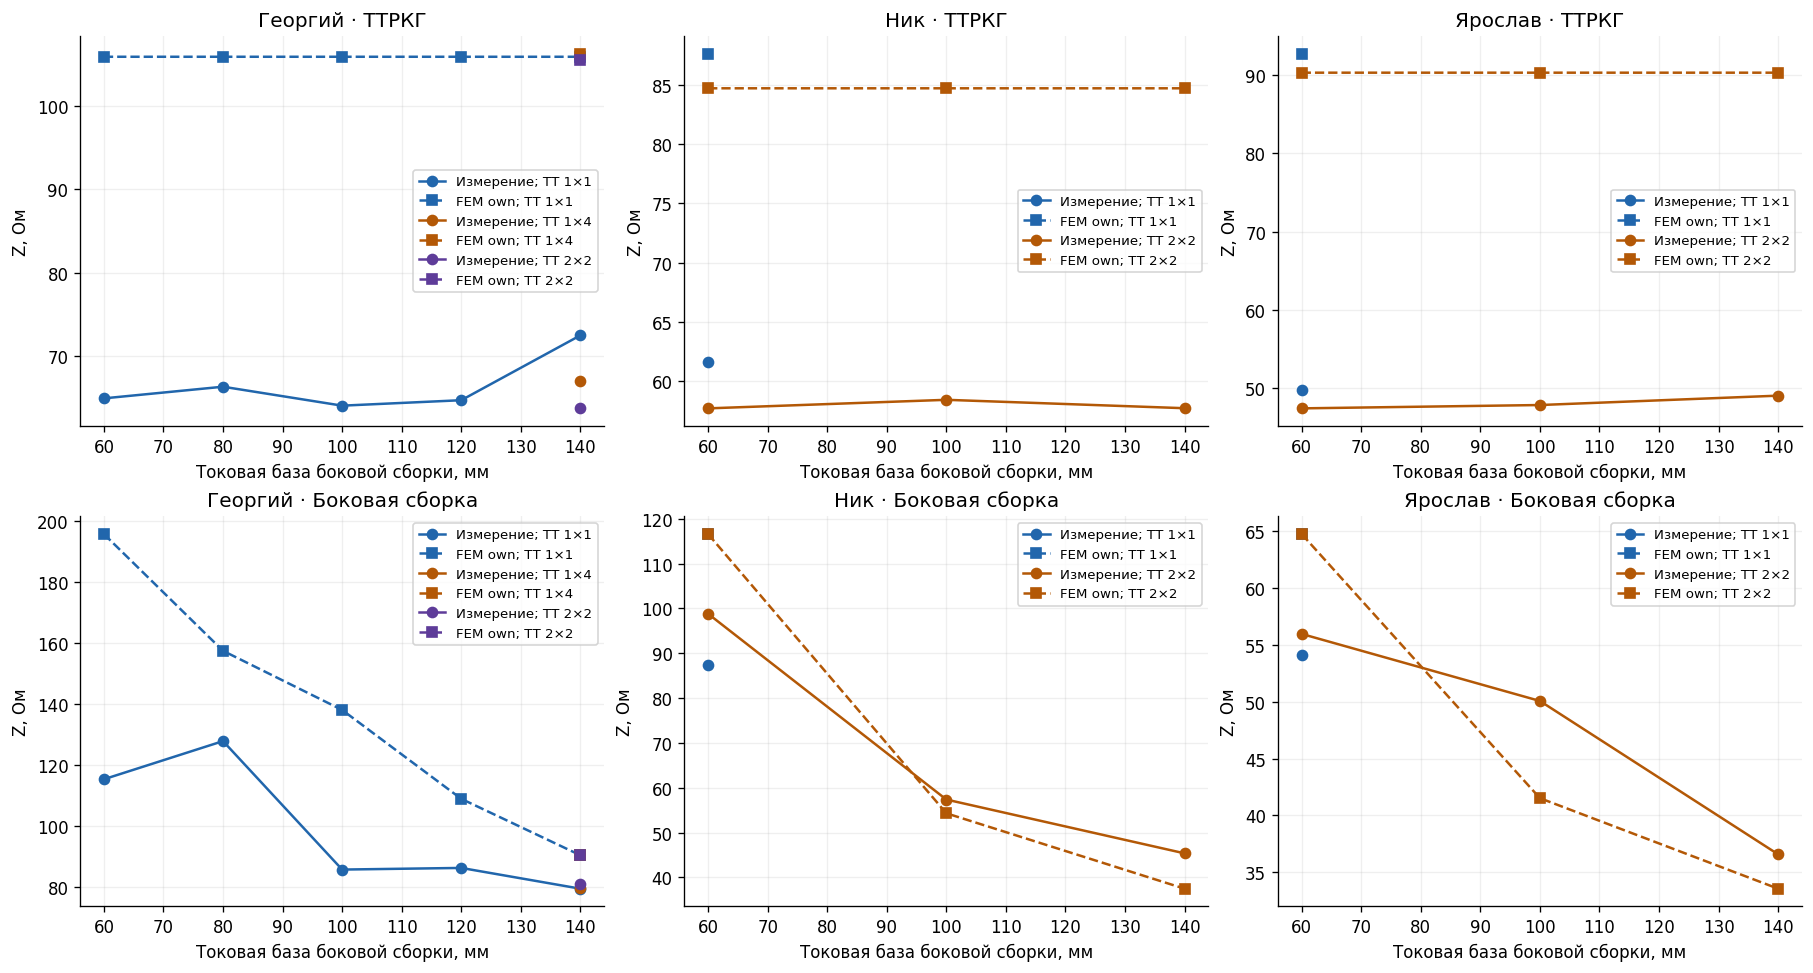

In [4]:
F.show_figure(F.fig_baseline(S))

**Рисунок 1. Измеренные медианные уровни и FEM-прогноз own_drive на вдохе при подтверждённом временном разделении каналов. Столбцы — участники; верхний ряд — ТТРКГ, нижний — боковая сборка. Цвет различает вариант ТТРКГ, сплошные линии с кружками — наблюдение, пунктир с квадратами — модель. База указана по боковой сборке.**

На рисунке 1 представлены прямые прогнозы для заданных материалов и CEM без подгонки сопротивлений или усиления. Невязки первичного монтажа 140 мм/2×2: Георгий: ТТРКГ +41.707 Ом, Боковая сборка +9.438 Ом; Ник: ТТРКГ +26.967 Ом, Боковая сборка -7.887 Ом; Ярослав: ТТРКГ +41.397 Ом, Боковая сборка -3.024 Ом. Эти различия относятся к выбранным материалам, геометрии и контактам; совпадение формы размерной зависимости не заменяет проверки абсолютных уровней.

Для подтверждённого режима используются ZТТРКГ=T(2,1) и
Zбок=T(4,3) (1), где T — сохранённая матрица портовых передач.
Перекрёстные передачи T(2,3) и T(4,1) оставлены отдельно для контроля
ответов и взаимосвязей портов. При временном разделении они не прибавляются
к собственному ответу и не входят в основной прогноз измеряемого Z.
Таблица 3 относится к первичному монтажу 140 мм и ТТРКГ 2×2 на вдохе.

In [5]:
display(HTML(F.drive_table(S)))

Участник,Отведение,"Измерение, Ом","Прогноз own_drive, Ом","Перекрёстная передача cross, Ом"
Георгий,ТТРКГ,"63,73","105,437","-22,5293"
Георгий,Боковая сборка,"80,9534","90,3919","-9,37802"
Ник,ТТРКГ,"57,7355","84,7024","-15,9266"
Ник,Боковая сборка,"45,3529","37,4656","-7,12723"
Ярослав,ТТРКГ,"48,9601","90,3573","-15,2623"
Ярослав,Боковая сборка,"36,5591","33,5355","-7,19631"


Ненулевые перекрёстные передачи характеризуют ответ измерительной пары на ток соседней пары в модели. Они сохраняют самостоятельное диагностическое значение; основной ответ при подтверждённом временном разделении определяется своим источником.

<a id="breath"></a>
## 3. Парное различие между вдохом и выдохом

Дыхательный контраст определяется как ΔZ=Zвыдох−Zвдох (2). Каждая разность
формируется внутри одной записи и отведения до объединения повторений.
Это сохраняет парность сравнения и отделяет контраст от абсолютного уровня.
В этом FEM-сценарии меняется только сопротивление лёгкого:
9,315252925→3,681694081 Ом·м. Сопротивления фона, кости, целого сердца и жира
фиксированы, исходная КТ глубокого вдоха остаётся неизменной. Следовательно,
модельный выдох является условным материальным сценарием.
Изолированный конечный ответ lung-only совпадает с тем же расчётом выдоха;
background-only даёт нулевой контраст по конструкции сценария. Это не
эмпирический результат «фон не меняется при дыхании». Поэтому идентичные
задачи прямого расчёта повторно не решались: проверены сохранённые пары
вдох/выдох и три источника расчёта вкладов каждого участника. Конечное
изменение ответа и его локальная линейная аппроксимация различаются;
равенство lung-only и полного конечного контраста не утверждает их равенства
линейному прогнозу Jacobian.

Проверим величину и знак парного контраста для каждого монтажа (рисунок 2).

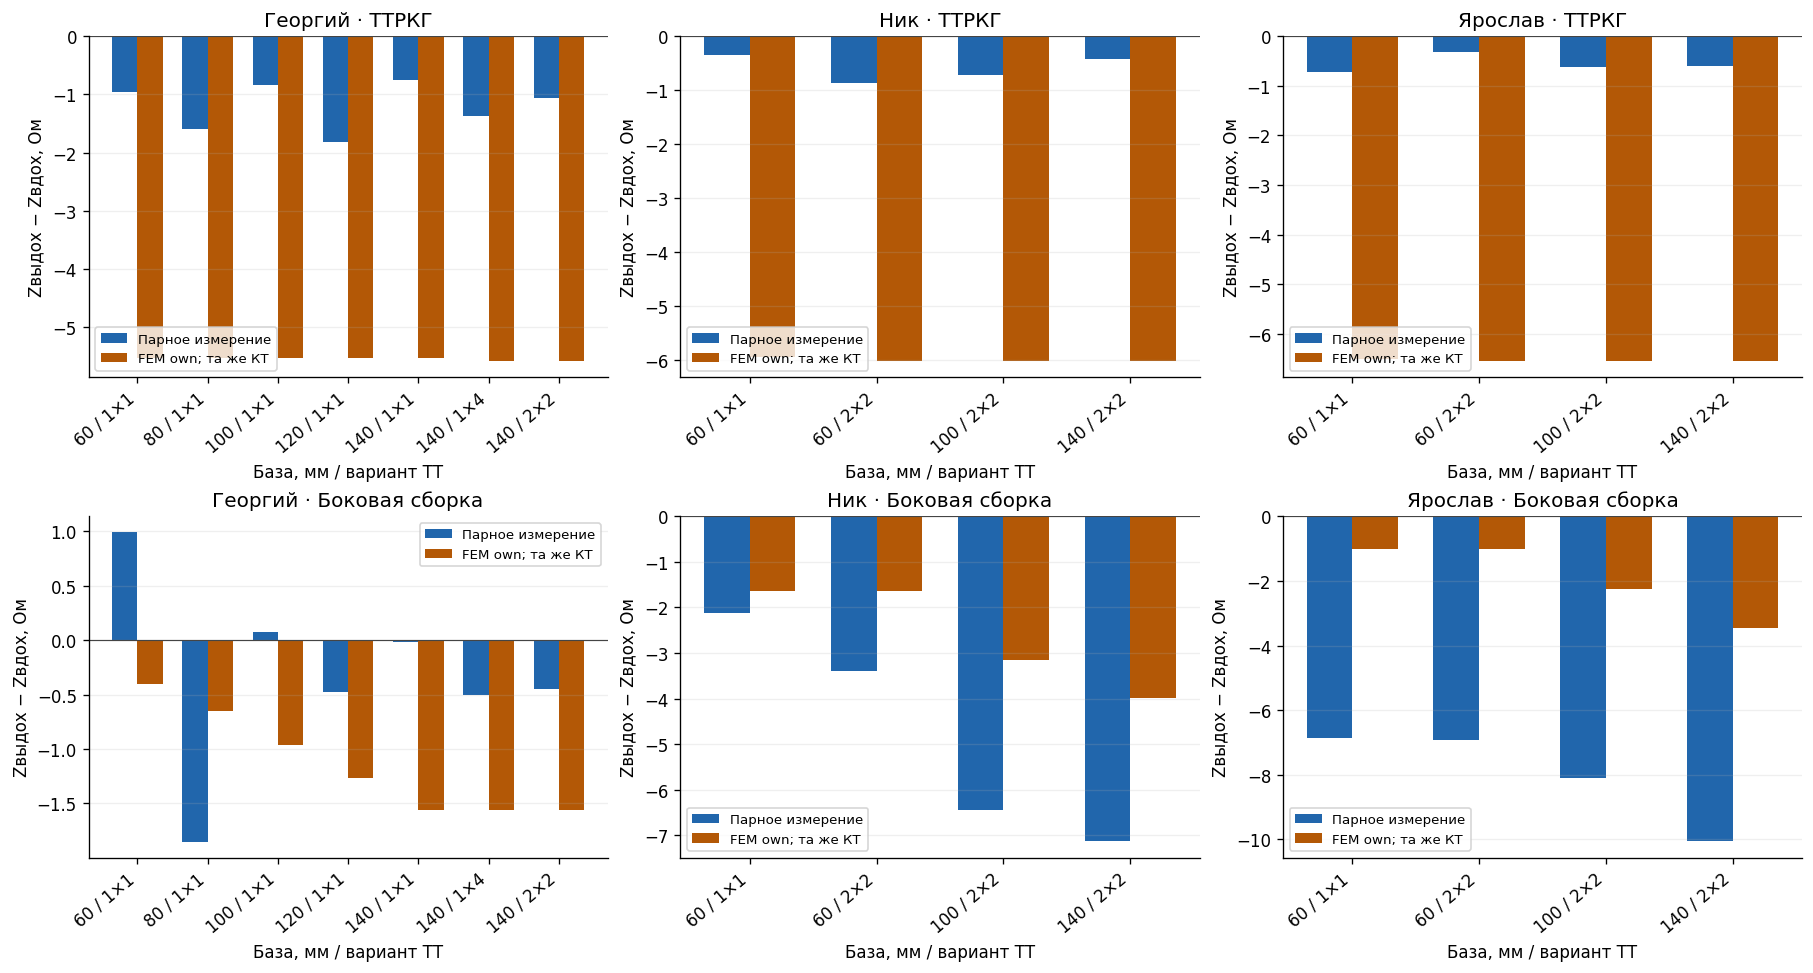

In [6]:
F.show_figure(F.fig_breath(S))

**Рисунок 2. Парные дыхательные разности: наблюдение и модельный lung-only контраст own_drive при временном разделении. Синий столбец — медиана парных разностей, оранжевый — модель. Категории обозначают базу боковой сборки в миллиметрах и вариант ТТРКГ.**

По рисунку 2: Георгий: первичный ТТРКГ — наблюдение -1.068 Ом, модель -5.578 Ом; число боковых монтажей с различным знаком наблюдения и модели — 2; Ник: первичный ТТРКГ — наблюдение -0.4164 Ом, модель -6.014 Ом; число боковых монтажей с различным знаком наблюдения и модели — 0; Ярослав: первичный ТТРКГ — наблюдение -0.602 Ом, модель -6.538 Ом; число боковых монтажей с различным знаком наблюдения и модели — 0. Геометрическое изменение грудной клетки здесь не рассчитывалось. Ретроспективная разметка, последовательность монтажей и отсутствие оценки межсессионной неопределённости ограничивают количественную интерпретацию расхождения.

<a id="svd"></a>
## 4. Локальная различимость четырёх сопротивлений

Сохранённый adjoint Jacobian задаёт Jlog=dZ/dlnρ. Его столбцы соответствуют
фону, лёгкому, всему сердцу и жиру; кость фиксирована. Ненормированная
производная равна dZ/dρj=Jlog,j/ρj (3), с единицами 1/м.
Для сравнения масштабов используется явно безразмерная матрица
Eij=Jlog,ij/Zi (4). Знаки Z и производных сохранены; эта нормировка не задаёт
шумовую дисперсию. SVD разлагает E на ортогональные направления, а сингулярные
числа характеризуют величину ответа на возмущения lnρ в этих направлениях.

Боковые строки, ТТРКГ и их совместный набор рассматриваются раздельно.
Совместный набор объединяет все сохранённые монтажи одного участника и состояния.
Одна пара ТТРКГ/боковой сборки даёт два наблюдения для четырёх rho.
Формальный ранг при машинном пороге не доказывает практической определимости.
Эти сравнения служат диагностической проверкой; совместный набор с боковыми
сборками не предлагается как дальнейшая рабочая схема определения ρ.
Один сигнал ТТРКГ сам по себе также не идентифицирует четыре произвольных
тканевых сопротивления без дополнительных ограничений и референсов.

Сопоставим сингулярный спектр с наблюдаемым изменением матрицы при смене правила интегрирования (рисунок 3).

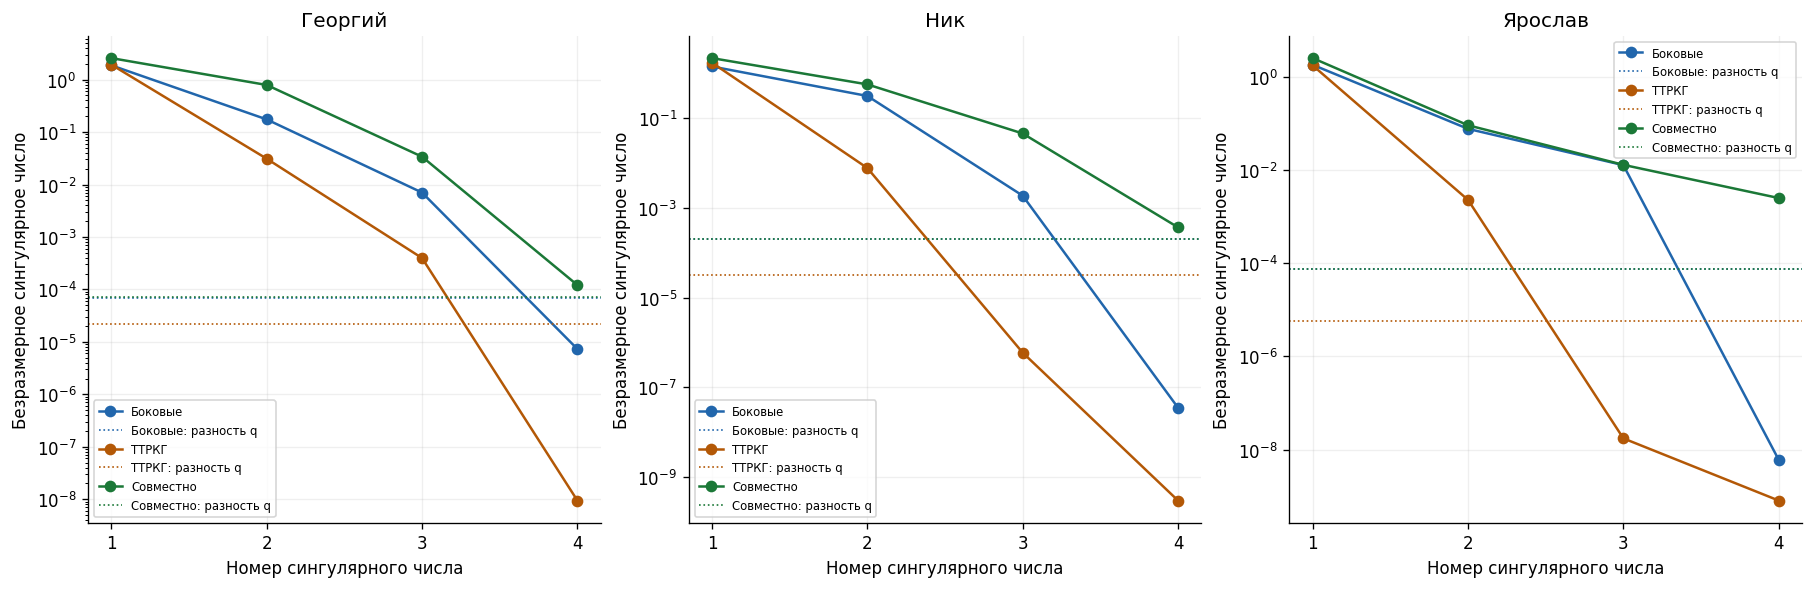

In [7]:
F.show_figure(F.fig_svd(S))

**Рисунок 3. Сингулярные числа безразмерной E на вдохе, логарифмическая шкала. Сплошные линии — боковые, ТТРКГ и совместный набор; цветные пунктирные уровни — спектральная норма Eq4096−Eq1024 для соответствующего набора.**

Обусловленность на рисунке 3: Георгий: боковые 2.56e+05, ТТРКГ 2.04e+08, совместно 2.12e+04; Ник: боковые 3.93e+07, ТТРКГ 5.57e+09, совместно 5.84e+03; Ярослав: боковые 3.04e+08, ТТРКГ 2.22e+09, совместно 1.01e+03. Слабейшее совместное направление у всех трёх участников преимущественно связано с эффективным сопротивлением всего сердца. Разность интеграционных правил является наблюдаемым численным контролем, её нельзя считать строгой границей ошибки. Шум и неопределённость положения не оценены; раздельная практическая оценка четырёх rho не установлена.

<a id="basis"></a>
## 5. Четыре знаковых тканевых возмущения

Для первичного монтажа задаются четыре независимых базисных сценария:
δlnρj=0,01 для одного материала, остальные возмущения равны нулю.
Линейный прогноз δZ≈Jlog·δlnρ (5) вычисляется по сохранённым производным.
Это заданные малые возмущения свойств тканей; их амплитуда не измерена
как пульсовое изменение участника. Кость и геометрия остаются постоянными.

Сравним знаки и масштабы ответа двух отведений на одинаковое логарифмическое возмущение (рисунок 4).

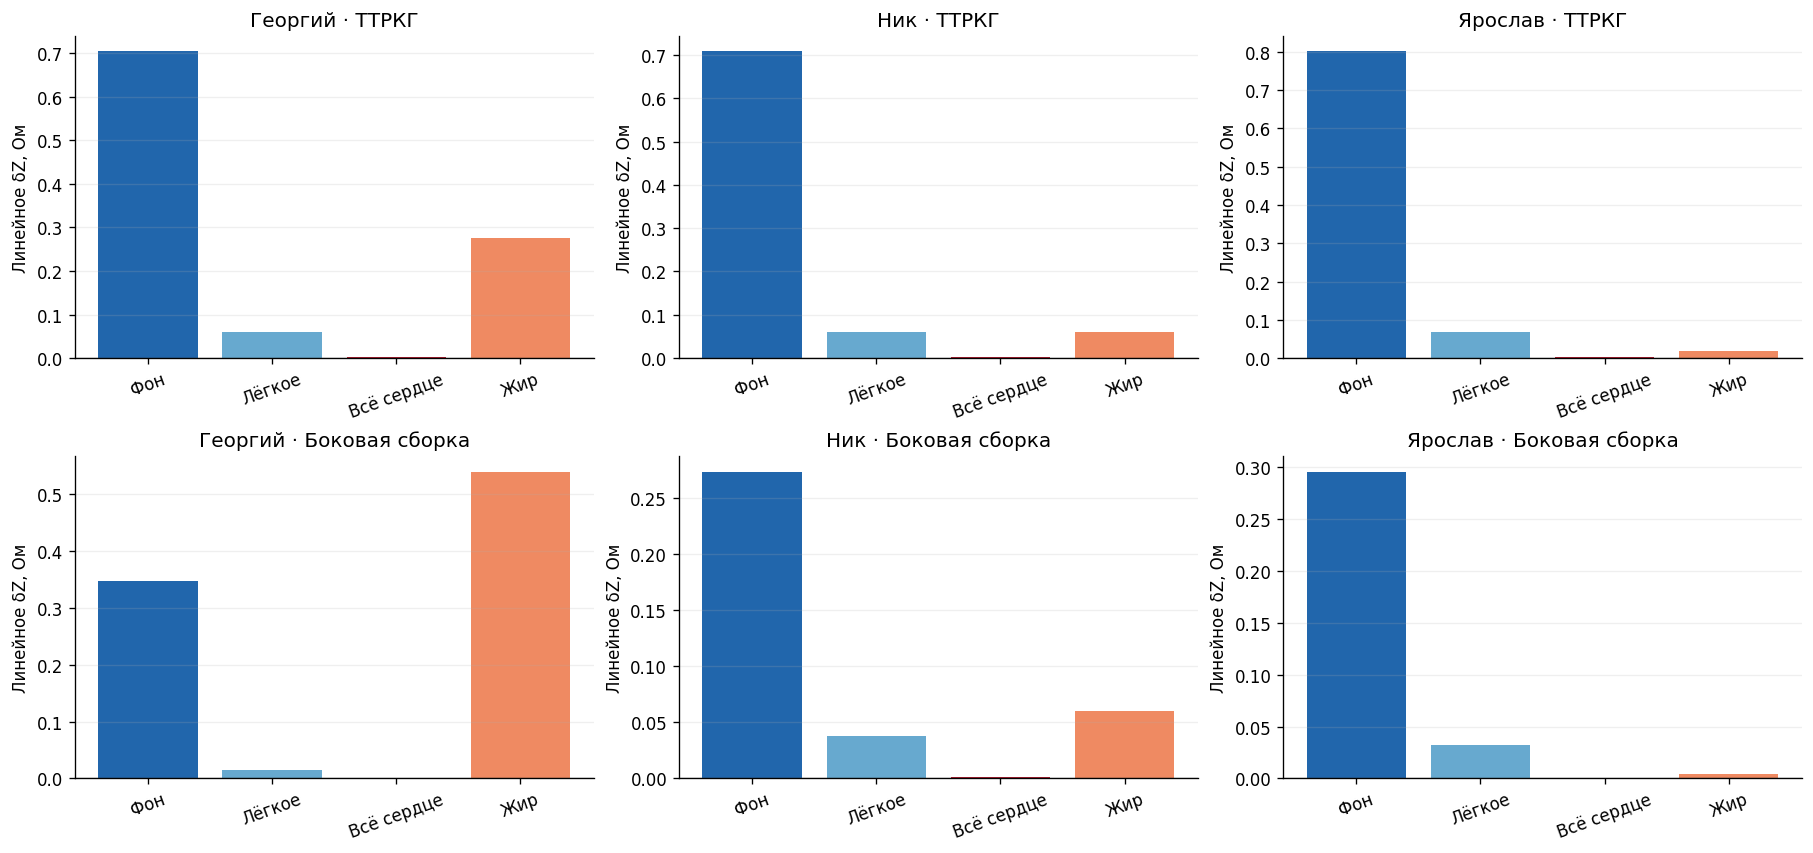

In [8]:
F.show_figure(F.fig_basis(S))

**Рисунок 4. Линейное δZ для четырёх базисных сценариев δlnρ=0,01 на вдохе. Монтаж 140 мм/ТТРКГ 2×2, q4096. Каждый столбец соответствует самостоятельному возмущению; одновременно они не суммируются.**

На рисунке 4 ответ ТТРКГ на изолированное δlnρ целого сердца=0,01 составляет: Георгий +0.00371678 Ом; Ник +0.0032691 Ом; Ярослав +0.00360361 Ом. Знак передаточной чувствительности определяется полями токовой и измерительной пар. Полученные столбцы не являются измеренными источниками пульса; ЭКГ-синхронность не разделяет их автоматически. Точность линейного приближения для выбранной конечной амплитуды здесь отдельно не проверена.

<a id="sphere"></a>
## 6. Эквивалентная сфера и объёмная чувствительность

Сфера строится по объёму маски всего сердца конкретного участника.
Рассматриваются целевые объёмы 0,95V₀, V₀ и 1,05V₀ при фиксированном центре.
Исходная область сердца заменяется фоном; внутри сферы материал сердца имеет
приоритет, после выхода сферы восстанавливается фоновый материал.
Это явное назначение материалов на неподвижной КТ, без механического переноса органов.
Контроль с исходной маской целого сердца должен воспроизвести базовый расчёт до
интерпретации изменения формы. Три объёмных состояния задают секущую;
сходимость по шагу объёма и обратная задача этим не проверены.

Рассмотрим только фактически сохранённые прямые ответы объёмных вариантов (рисунок 5).

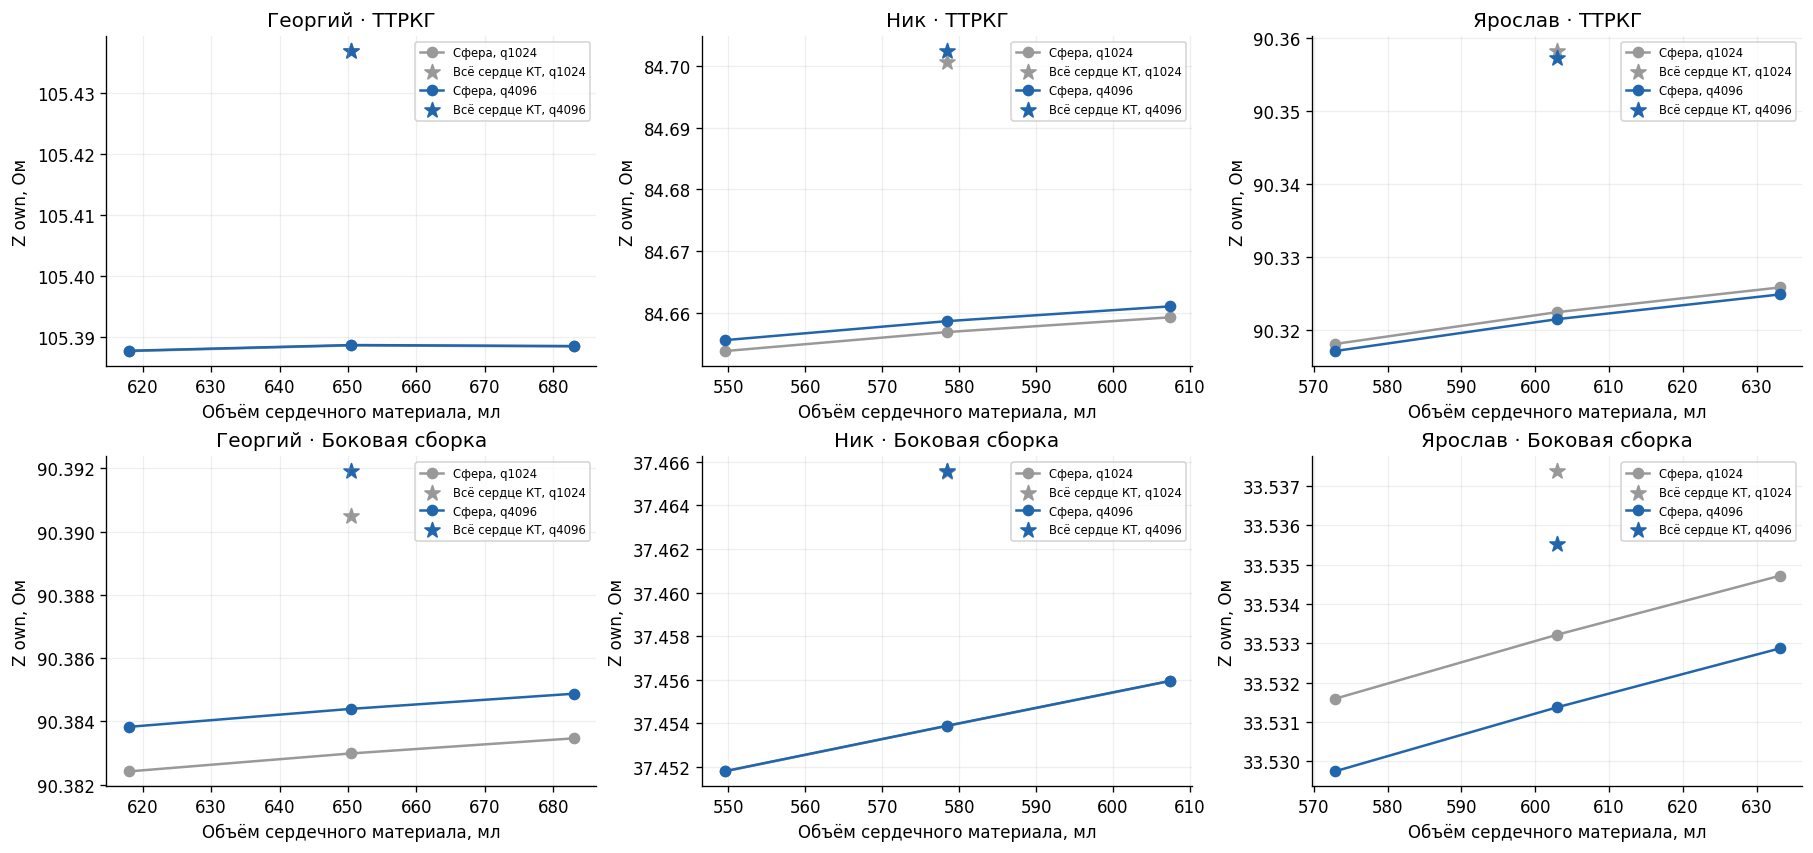

In [9]:
F.show_figure(F.fig_sphere(S))

**Рисунок 5. Импеданс own_drive в зависимости от интегрированного объёма сердечного материала. Кружки и линии — три сферических состояния, звёзды — исходная маска целого сердца; серый — q1024, синий — q4096. Контрольный профиль: ρфона=2,763586, ρлёгкого=9,315253, ρцелого сердца=4,648809 Ом·м; жир и кость фиксированы.**

Рисунок 5 сопоставляет геометрию при одном фиксированном векторе сопротивлений: замена исходной маски сферой и изменение объёма сферы рассматриваются внутри указанного контрольного профиля. Размах модельных объёмов не является ударным объёмом. Объёмная чувствительность не переводится в УО/ФВ без отдельной проверенной связи с физиологическими камерными объёмами.

**Фактический контроль формы и объёма.** Георгий: изменение ТТРКГ при равнообъёмной замене формой сферы -0.0482928 Ом, отклик между 0,95V₀ и 1,05V₀ +0.000776757 Ом, разность q для собственного ТТРКГ сферы V₀ +6.30965e-05 Ом; Ник: изменение ТТРКГ при равнообъёмной замене формой сферы -0.0437484 Ом, отклик между 0,95V₀ и 1,05V₀ +0.00546931 Ом, разность q для собственного ТТРКГ сферы V₀ +0.00177139 Ом; Ярослав: изменение ТТРКГ при равнообъёмной замене формой сферы -0.0357752 Ом, отклик между 0,95V₀ и 1,05V₀ +0.00775863 Ом, разность q для собственного ТТРКГ сферы V₀ -0.00095943 Ом. Если эффект формы превосходит проверенный объёмный контраст, объём сферы особенно нельзя отождествлять с анатомическим объёмом. Эти два эффекта сопоставлены в омах; пересчёт ошибки формы в миллилитры по секущей не выполняется. Разность интегрирования собственного ТТРКГ отделена от максимума по всем элементам портовой матрицы.

<a id="range"></a>
## 7. Авторский диапазон сопротивлений и отдельный сценарий всего сердца

**Авторское условие новой ветви.** Мягкотканному фону назначается диапазон
2–3 Ом·м, лёгкому — 2–12 Ом·м, всему сердцу — однородное 1,35 Ом·м.
Значение крови используется здесь как заданное свойство всей сердечной области;
смесь крови и миокарда им независимо не определена. Жир и кость фиксированы.
Диапазон мышц присвоен эффективному фону неразмеченных мягких тканей;
самостоятельная анатомическая маска мышц в этой постановке отсутствует.
Сканирование использует фон 2; 2,5; 3 Ом·м и лёгкое 2; 4; 7; 10; 12 Ом·м:
15 точек q4096 и пять контрольных точек q1024. Это сценарная сетка, а не
доверительный диапазон индивидуальных параметров. Отдельные восемь объёмных
результатов новой ветви вычисляются при фоне 2,5, лёгком 7 и сердце 1,35 Ом·м.

Новые прямые результаты принимаются только по собственным завершённым
планам и SHA. Прогноз own_drive соответствует подтверждённому временному
разделению каналов и сопоставляется без подгонки усиления.
Диапазон Z по такой сетке нельзя восстановить из контрольного
расчёта при сопротивлении целого сердца 4,6488 Ом·м
или линейной экстраполяцией. Таблица 4 показывает фактическую готовность.

In [10]:
display(HTML(F.status_table(S)))

Участник,Замещение сердца: готово / 8,Сканирование диапазона,"Сфера при 1,35 Ом·м"
Георгий,8,completed,completed
Ник,8,completed,completed
Ярослав,8,completed,completed


Скриншот расчёта коллеги служит качественным ориентиром изменения ответа
при повышении сопротивления фона и лёгкого. Исходный файл, геометрия и определение
измеряемого Z недоступны. По уточнению автора возможна двуслойная сфера
«миокард + кровь»; текущая первая ветвь по его поручению использует однородную
кровь 1,35 Ом·м. Скриншот не оцифровывается и не служит независимой валидацией.

Для центра новой сетки ρфон=2,5, ρлёгкое=7, ρсердце=1,35 Ом·м заново
используется собственный Jlog этой точки. Таблица 6 раздельно показывает
четыре столбца и редуцированные [фон, лёгкое] при фиксированных сердце, жире
и кости. Одна первичная пара даёт две строки и не определяет четыре rho.
Полный ранг редуцированной матрицы означает лишь локальную условную
определимость при перечисленных фиксированных параметрах; реальные
индивидуальные сопротивления этим не восстановлены. Таблица 5 сохраняет
границы сценарной сетки Z без интерпретации их как доверительных интервалов.


In [11]:
display(HTML(F.range_tables(S)))

Участник,Монтаж,Отведение,Режим возбуждения,"Z мин., Ом","Z макс., Ом",Точек
Георгий,L100_TT1x1,ТТРКГ,own_drive · временное разделение,"77,2309","113,083",15
Георгий,L100_TT1x1,Боковая сборка,own_drive · временное разделение,"118,216","143,017",15
Георгий,L120_TT1x1,ТТРКГ,own_drive · временное разделение,"77,2307","113,083",15
Георгий,L120_TT1x1,Боковая сборка,own_drive · временное разделение,"93,6105","112,684",15
Георгий,L140_TT1x1,ТТРКГ,own_drive · временное разделение,"77,2308","113,083",15
Георгий,L140_TT1x1,Боковая сборка,own_drive · временное разделение,"77,4804","93,5676",15
Георгий,L140_TT1x4,ТТРКГ,own_drive · временное разделение,"78,0271","113,282",15
Георгий,L140_TT1x4,Боковая сборка,own_drive · временное разделение,"77,4767","93,5626",15
Георгий,L140_TT2x2,ТТРКГ,own_drive · временное разделение,"77,3454","112,453",15
Георгий,L140_TT2x2,Боковая сборка,own_drive · временное разделение,"77,4777","93,564",15


**Собственные результаты новой материальной точки.** Георгий: первичная пара имеет ранг 2 из четырёх и размерность ядра 2; при свободных фоне и лёгком κ=49.131. Максимальная относительная ошибка FD центра 7.90033e-08; q-контроль пройден для 35 из 105 комбинаций точка/монтаж; Ник: первичная пара имеет ранг 2 из четырёх и размерность ядра 2; при свободных фоне и лёгком κ=36.9553. Максимальная относительная ошибка FD центра 8.15808e-08; q-контроль пройден для 20 из 60 комбинаций точка/монтаж; Ярослав: первичная пара имеет ранг 2 из четырёх и размерность ядра 2; при свободных фоне и лёгком κ=69.1529. Максимальная относительная ошибка FD центра 1.19507e-07; q-контроль пройден для 20 из 60 комбинаций точка/монтаж. FD относится только к первичному монтажу центра. Второе правило интегрирования рассчитано в углах сетки и в центре; остальные точки не получили отдельного q-контроля. Условная определимость двух параметров требует фиксированных свойств сердца, жира и кости; эти свойства не установлены индивидуальными измерениями.

**Совместное сопоставление на сетке, own_drive.** Георгий: вдох: измеренные [ТТРКГ; боковая] = [63.729950; 80.953440] Ом. Среди 15 точек минимальная норма двух невязок 14.0521 Ом при [ρфона; ρлёгкого]=[2; 2] Ом·м, знаковые невязки [+13.6154; -3.47576] Ом. По всем 14 наблюдениям минимум RMS 17.6653 Ом при [2; 2] Ом·м; выдох: измеренные [ТТРКГ; боковая] = [62.661990; 80.507160] Ом. Среди 15 точек минимальная норма двух невязок 14.9927 Ом при [ρфона; ρлёгкого]=[2; 2] Ом·м, знаковые невязки [+14.6834; -3.02948] Ом. По всем 14 наблюдениям минимум RMS 17.9282 Ом при [2; 2] Ом·м.

Ник: вдох: измеренные [ТТРКГ; боковая] = [57.735485; 45.352950] Ом. Среди 15 точек минимальная норма двух невязок 17.0103 Ом при [ρфона; ρлёгкого]=[2; 12] Ом·м, знаковые невязки [+7.44373; -15.2952] Ом. По всем 8 наблюдениям минимум RMS 9.02285 Ом при [2; 7] Ом·м; выдох: измеренные [ТТРКГ; боковая] = [57.319050; 38.220790] Ом. Среди 15 точек минимальная норма двух невязок 10.9561 Ом при [ρфона; ρлёгкого]=[2; 7] Ом·м, знаковые невязки [+5.53395; -9.4558] Ом. По всем 8 наблюдениям минимум RMS 6.78713 Ом при [2; 4] Ом·м.

Ярослав: вдох: измеренные [ТТРКГ; боковая] = [48.960130; 36.559055] Ом. Среди 15 точек минимальная норма двух невязок 18.7798 Ом при [ρфона; ρлёгкого]=[2; 2] Ом·м, знаковые невязки [+10.5385; -15.5441] Ом. По всем 8 наблюдениям минимум RMS 13.2279 Ом при [2; 2] Ом·м; выдох: измеренные [ТТРКГ; боковая] = [48.358150; 26.500060] Ом. Среди 15 точек минимальная норма двух невязок 12.4176 Ом при [ρфона; ρлёгкого]=[2; 2] Ом·м, знаковые невязки [+11.1405; -5.48515] Ом. По всем 8 наблюдениям минимум RMS 10.0872 Ом при [2; 2] Ом·м.

Невязка определена как модель минус измерение. Норма двух невязок равна √(rТТ²+rбок²), RMS — √(Σr²/n); все компоненты имеют одинаковый арифметический вес. Это описательные минимумы только среди рассчитанных точек, без модели шума, доверительных интервалов или оценки индивидуальных параметров. Они не исключают совпадение в непрерывном прямоугольнике сопротивлений. Представленные совместные невязки не подтверждают согласия обоих отведений с одним набором свойств при выбранных тканевых свойствах, геометрии и контактах. Режим возбуждения соответствует подтверждённому временному разделению.

**Проверка первичного ТТРКГ на тех же точках.** Георгий: ТТРКГ own_drive 77.345389–112.453263 Ом. Ниже всех рассчитанных точек находятся 2 из 2 наблюдаемых уровней; Ник: ТТРКГ own_drive 56.801646–91.917474 Ом. Ниже всех рассчитанных точек находятся 0 из 2 наблюдаемых уровней; Ярослав: ТТРКГ own_drive 59.498632–98.506102 Ом. Ниже всех рассчитанных точек находятся 2 из 2 наблюдаемых уровней. Сравниваются отдельно измеренные вдох и выдох без назначения дыхательных состояний сценарным точкам. Если уровень ниже минимального прогноза, ни одна из рассчитанных точек его не покрывает. Это не исключает иные непрерывные параметры и не отменяет неопределённость геометрии, контактных условий и свойств тканей.

Сравним фактически рассчитанную 15-точечную сетку с двумя наблюдаемыми дыхательными уровнями (рисунок 6).

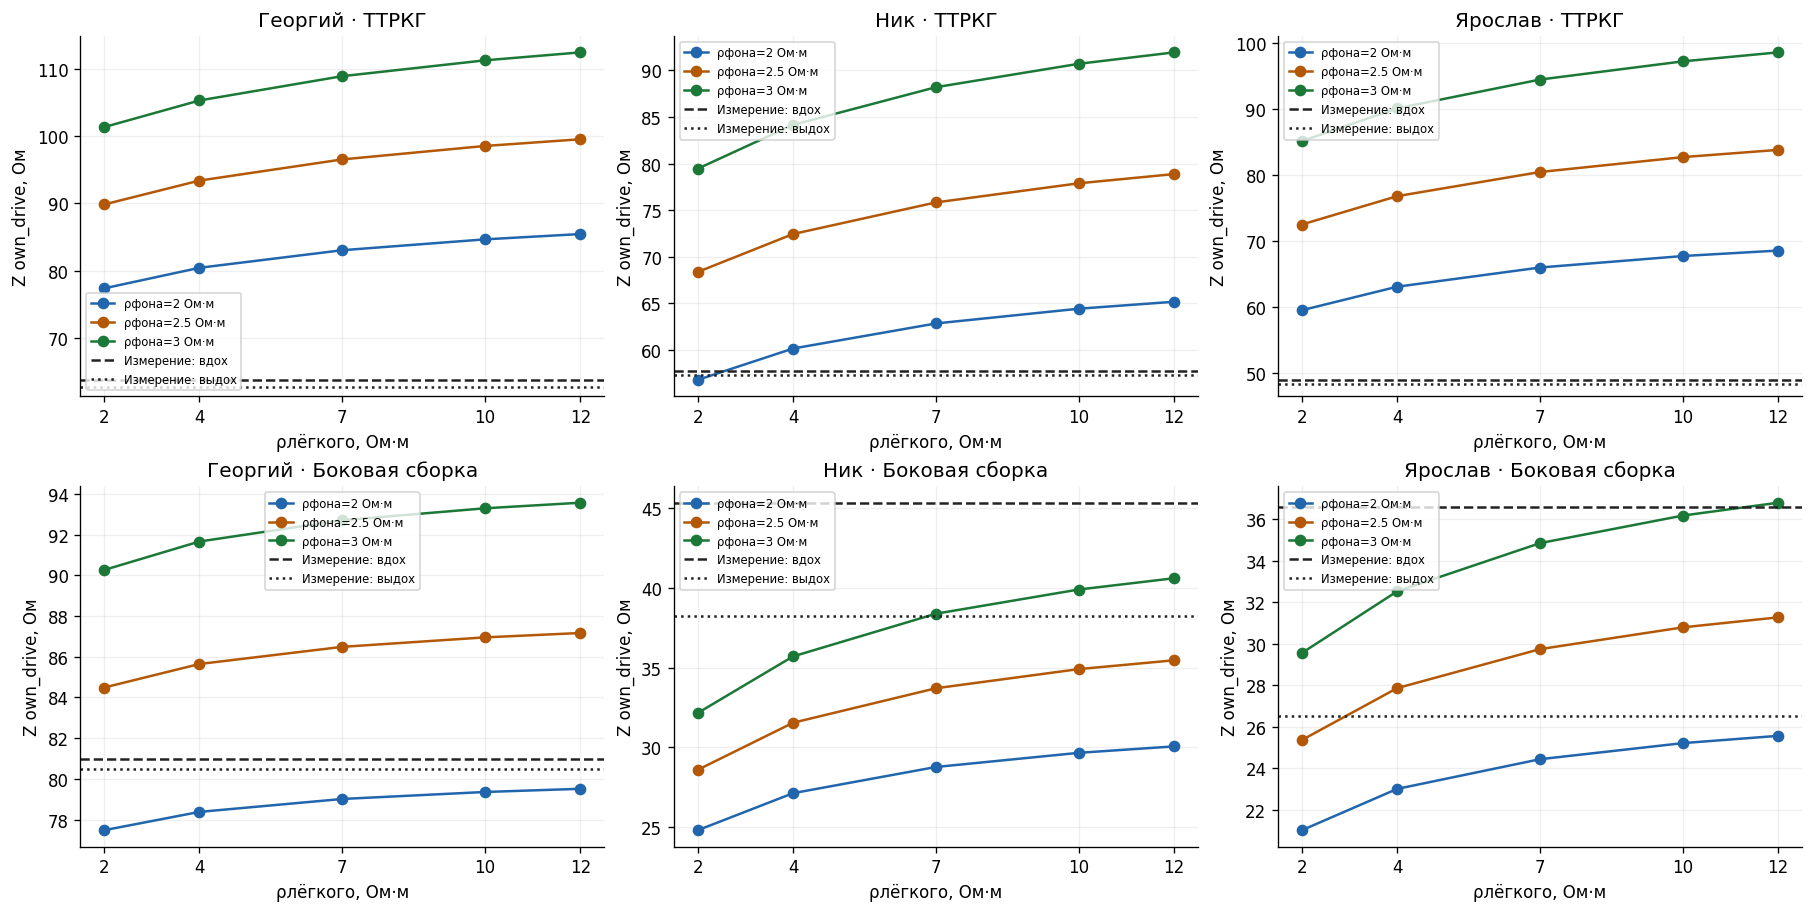

In [12]:
F.show_figure(F.fig_material_grid(S))

**Рисунок 6. Новая сетка сопротивлений для 140 мм/ТТРКГ 2×2, q4096, ρцелого сердца=1,35 Ом·м. По оси X — ρлёгкого, три цветные линии соединяют пять рассчитанных точек при ρфона 2; 2,5; 3 Ом·м. Горизонтальные линии — измеренные медианы вдоха и выдоха. Жир и кость фиксированы; own_drive соответствует подтверждённому временному разделению каналов.**

На рассчитанных точках рисунка 6 диапазон own_drive составляет: Георгий: ТТРКГ 77.3454–112.453 Ом, Боковая сборка 77.4777–93.564 Ом; Ник: ТТРКГ 56.8016–91.9175 Ом, Боковая сборка 24.7971–40.6119 Ом; Ярослав: ТТРКГ 59.4986–98.5061 Ом, Боковая сборка 21.0149–36.7875 Ом. Каждая отмеченная точка является сохранённым прямым расчётом. Соединяющие отрезки организуют точки; дополнительные значения между ними не рассчитывались. Сценарным точкам свойств тканей не назначается состояние вдоха или выдоха: оба измеренных уровня показаны как отдельные ориентиры. Совпадение уровня с точкой не устанавливает единственность сопротивлений или индивидуальную физиологическую оценку.

Рассмотрим геометрическое сравнение внутри нового фиксированного материального профиля (рисунок 7).

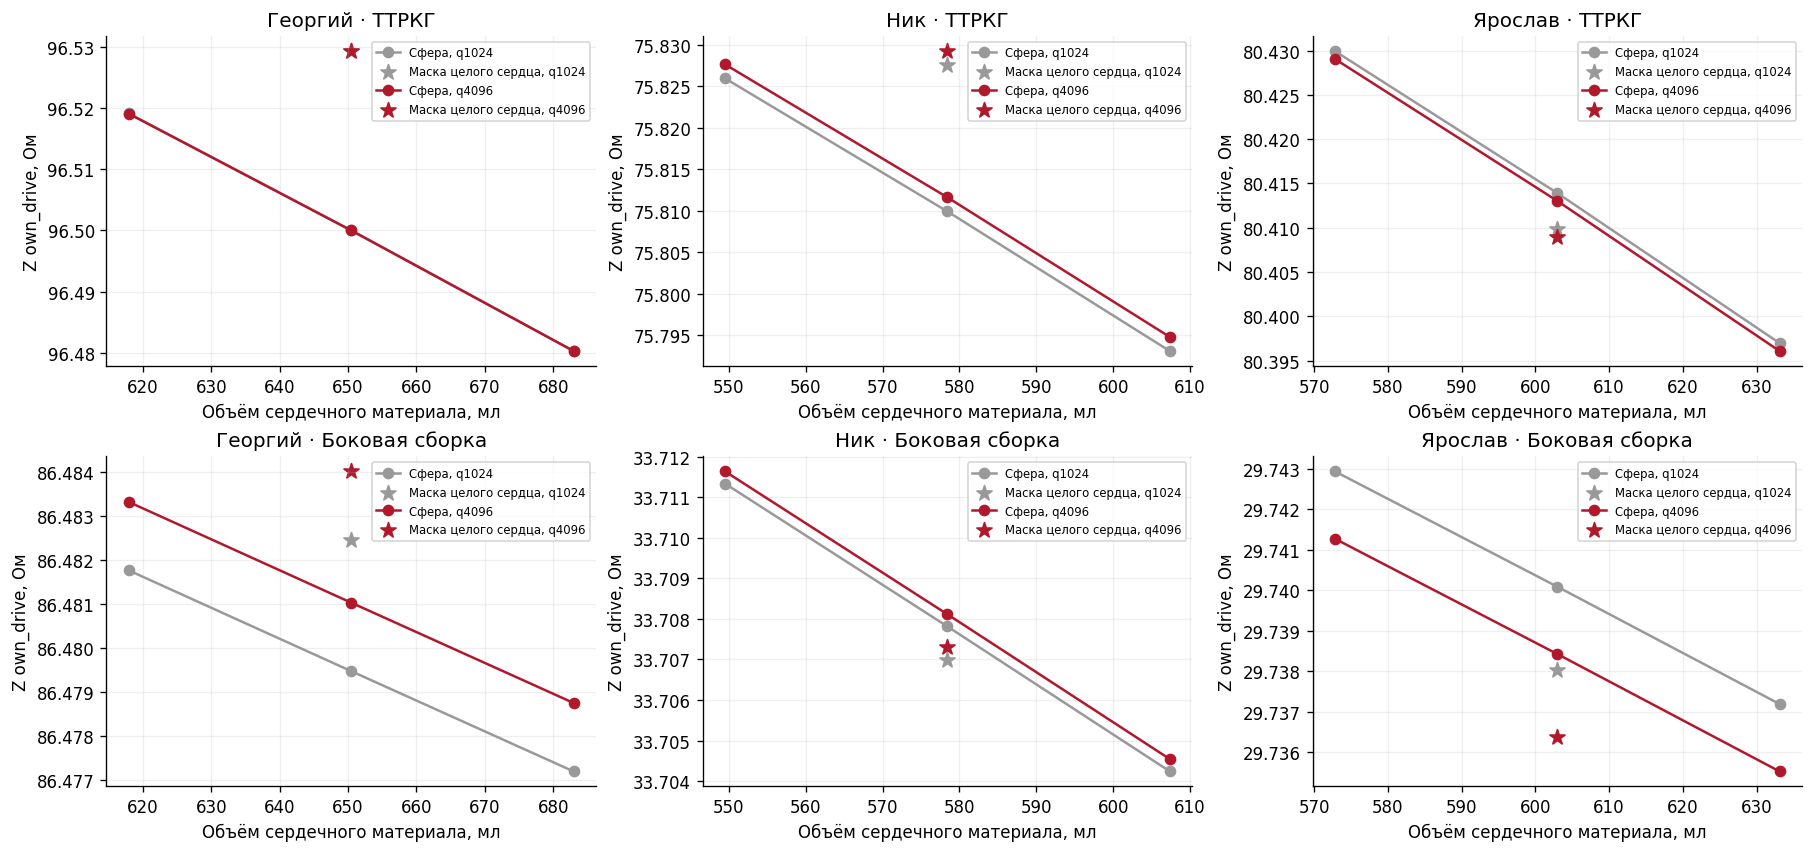

In [13]:
F.show_figure(F.fig_blood_sphere(S))

**Рисунок 7. Объёмные ответы own_drive при ρфона=2,5, ρлёгкого=7 и ρцелого сердца=1,35 Ом·м. Кружки — сферы с тремя объёмами, звёзды — исходная маска целого сердца при тех же свойствах. Серый — q1024, красный — q4096. На оси X — интегрированный объём, мл.**

Сохранённые результаты рисунка 7: Георгий: ТТРКГ, сфера V₀ минус исходная маска -0.0292936 Ом; ответ между 0,95V₀ и 1,05V₀ -0.0388104 Ом. Разности q4096−q1024 для этих контрастов формы и объёма соответственно +3.03182e-06 и +4.92967e-06 Ом; для абсолютного Z сферы V₀ отдельно -3.64478e-05 Ом. Контроль исходной маски с центром сетки сопротивлений при q4096: точное совпадение; FD-проверка этой объёмной ветви не выполнялась; Ник: ТТРКГ, сфера V₀ минус исходная маска -0.0176223 Ом; ответ между 0,95V₀ и 1,05V₀ -0.0328301 Ом. Разности q4096−q1024 для этих контрастов формы и объёма соответственно -7.23516e-06 и +1.03971e-05 Ом; для абсолютного Z сферы V₀ отдельно +0.00169508 Ом. Контроль исходной маски с центром сетки сопротивлений при q4096: точное совпадение; FD-проверка этой объёмной ветви не выполнялась; Ярослав: ТТРКГ, сфера V₀ минус исходная маска +0.00403742 Ом; ответ между 0,95V₀ и 1,05V₀ -0.032984 Ом. Разности q4096−q1024 для этих контрастов формы и объёма соответственно -9.47339e-06 и +1.26727e-05 Ом; для абсолютного Z сферы V₀ отдельно -0.000898555 Ом. Контроль исходной маски с центром сетки сопротивлений при q4096: точное совпадение; FD-проверка этой объёмной ветви не выполнялась. Для этой ветви используются собственные материальные блоки каждого объёмного варианта. Внутри рисунка 7 геометрия сравнивается при неизменных сопротивлениях всех материалов. Между рисунками 5 и 7 одновременно изменены сопротивления фона, лёгкого и целого сердца: их разность относится ко всему материальному профилю, а не к изолированному свойству крови. Однофакторное сравнение только ρ целого сердца при постоянных фоне и лёгком не проводилось. Разность сферы и маски при одинаковом целевом объёме характеризует эффект формы внутри заданного профиля; три точки не дают обоснования для расчёта ударного объёма или экстраполяции секущей за проверенный диапазон.

<a id="conclusion"></a>
## 8. Вывод и воспроизведение

**Модельный результат.** Индивидуальные прямые модели дают знаковые базовые
ответы, локальные производные и условный дыхательный контраст при явно заданных
материалах и источниках. В диагностическом сравнении совместный набор монтажей
улучшает обусловленность по сравнению с каждым отведением отдельно; слабое
направление, связанное с сердцем, сохраняется. Надёжное индивидуальное
определение тканевых ρ в проверенной постановке не получено. Этот результат
ограничен рассмотренными моделями, измерениями и сценариями; универсальная
теорема неприменимости боковых сборок для любых условий не утверждается.

**Решение автора и граница его обоснования.** Конечным входом дальнейшей
методики выбран только сигнал ТТРКГ. Боковые результаты сохраняются как
отрицательная проверка и не становятся предлагаемой рабочей инверсией ρ.
Это принятое направление разработки; его выбор сам по себе не валидирует
оценку сердечной функции по ТТРКГ. Свойства тканей для этой ветви остаются
сценарными либо референсными. Один сигнал или одна пара отведений не
идентифицирует произвольно четыре тканевых ρ; дополнительные предпосылки
и независимые проверки остаются необходимыми.

**Экспериментальное сопоставление.** Абсолютные уровни и парные разности
сопоставлены отдельно. Контактные условия, геометрия, тканевые свойства,
ретроспективно выделенные дыхательные интервалы и состояние между последовательными монтажами
ограничивают объяснение невязок. Шесть отказов размещения не дают электрической
оценки его погрешности. Сеточная сходимость и клиническая валидация не доказаны;
УО/ФВ в этом вычислительном цикле не получены.

Отчёт читает сохранённые JSON и обезличенный агрегат. При чистом запуске
ноутбука выполняются загрузка агрегата, арифметическая постобработка и построение
семи рисунков; FEM, КТ и сигналы не пересчитываются. Полные источники доступны
локально, а ниже сохранены только относительные пути и SHA. HTML экспортируется
без исходного Python-кода. Окончательная готовность входов не повышает
доказательный статус научных выводов.

**Совместность новой материальной сетки.** Георгий: минимальная норма двух невязок на сетке 14.0521 Ом для вдоха и 14.9927 Ом для выдоха; Ник: минимальная норма двух невязок на сетке 17.0103 Ом для вдоха и 10.9561 Ом для выдоха; Ярослав: минимальная норма двух невязок на сетке 18.7798 Ом для вдоха и 12.4176 Ом для выдоха. Эти числа относятся к own_drive при подтверждённом временном разделении и 15 рассчитанным точкам; непрерывный подбор сопротивлений здесь не выполнялся. Снижение отдельной невязки нельзя принимать за согласие обоих отведений.

In [14]:
display(HTML(F.table_html(['Относительный источник','SHA-256'],[[r['relative_path'],r['sha256']] for r in S['sources']],'Таблица 7. Происхождение сохранённых агрегатов и прямых результатов')))

Относительный источник,SHA-256
georg/cem/cem_contacts_manifest.local.json,ab6f8f67528f97b54485bc6e7b1db1c7a67cb8d3d723d335a6a16865dea2b0bc
georg/cem_contacts_input/cem_contacts_input.local.json,a00da9355909e60a3733743e6dde9adebbb659707809fb0a36395b7ce986d562
georg/electrical/forward.local.json,1df145f06fd3e69f4da3e88cae044b4bb6a79e95ed4188b0ad405016650bc3e3
georg/electrical_inputs.local.json,3ffb6d9fc4c04920b26305e191057b0c4451b421a5e8e6f91f8bbb6c04fcb2e6
georg/heart_linear_predictions.local.json,dc7fb3f4a6d5b2b2dfed98e8f583054ed464fb30714850c5d5a53de3a13a52db
georg/heart_pilot/plan.local.json,2f0335f0978e805646e1ecd9e25ec1444ce3a328894fd1171d587ed12e672479
georg/heart_pilot/solve_sphere_v095_q1024/report.local.json,ee81708705b8efe89b368423af3e01bf69a8958ba62cc3e74f4a9caed93d29c2
georg/heart_pilot/solve_sphere_v095_q4096/report.local.json,db44e3a6f5d083b9f6e167e338022d939c3ef4e4ab9bec0bbae12dba3de57f52
georg/heart_pilot/solve_sphere_v100_q1024/report.local.json,263d65d51d40edacee01ddf34565897e1cd82fb25adb477b3d689aa08fbf399e
georg/heart_pilot/solve_sphere_v100_q4096/report.local.json,c18b9c3a76d50337bf0b5f0d1aca403a13b7c95d85d91ca6b01f7d44dce39b13
